In [1]:
import cupy as cp
import pandas as pd
import seaborn as sns
import cuml
import matplotlib.pyplot as plt
import numpy as np
from xgboost import XGBRegressor
from cuml.ensemble import RandomForestRegressor
from hyperopt import hp, fmin, tpe, Trials, STATUS_OK
from cuml.metrics import r2_score as cuml_r2_score  # GPU Metrics
from cuml.model_selection import train_test_split as cuml_split
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import shap

/home/aashr/miniforge3/envs/rapids-26.08/lib/python3.12/site-packages/xgboost/_c_api.py:180: FutureWarning: `rapids-xgboost` will no longer be published in the `rapidsai` conda channel with the 26.10 release. Please use the `xgboost` package from `conda-forge`, or the `xgboost` wheel from the Python Package Index (PyPI). Consult https://docs.rapids.ai/notices/rsn0062/ for more details.
  warnings.warn(
/home/aashr/miniforge3/envs/rapids-26.08/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
data = pd.read_csv("/home/aashr/-/Py/Minor_Spec/Papers/1-s2.0-S2666016424001440-mmc1.csv")
data

,ID,Type of MB,Types of contaminants,pH,Compound Mw (g/mol),Compound charge,Compound Kow,min projection (Å),max projection (Å),MB MWCO (Da),MB contact angle (°),MB zeta potential,Total charge,Pressure (kPa),Measurement time (min),Initial concentration of compound (mg/L),compound size (nm),removal rate (%)
0,1,polypropylene (PP),2-(2-Butoxyethoxy)ethanol,7.0,162.229,0.0000,0.711,3.25,8.08,150,50.0,-1.0,0.0000,800.0,10.0,0.16223,0.512,81.5900
1,2,polypropylene (PP),Caprolactam,7.0,113.160,0.0000,0.310,3.92,4.01,150,50.0,-1.0,0.0000,800.0,10.0,0.11316,0.396,82.8500
2,3,polypropylene (PP),Creatine,7.0,131.135,0.0000,-2.864,3.35,4.36,150,50.0,-1.0,0.0000,800.0,10.0,0.13114,0.382,96.6500
3,4,polypropylene (PP),Formaldehyde,7.0,30.026,0.0000,-0.467,2.08,2.34,150,50.0,-1.0,0.0000,800.0,10.0,0.03003,0.221,3.3500
4,5,polypropylene (PP),Isopropanol,7.0,60.096,0.0000,0.255,2.95,3.36,150,50.0,-1.0,0.0000,800.0,10.0,0.06010,0.315,65.2700
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1901,1903,Poly(p-phenylene oxide) (PPO),Indomethacin,7.0,357.790,-1.0000,3.530,5.24,8.54,200,22.6,-1.0,1.0000,500.0,1440.0,0.02000,0.669,97.0719
1902,1904,Poly(p-phenylene oxide) (PPO),Cephalexin hydrate,7.0,347.390,-0.3711,-2.142,4.74,6.38,200,22.6,-1.0,0.3711,500.0,1440.0,0.02000,0.550,95.2613
1903,1905,Poly(p-phenylene oxide) (PPO),Diltiazem,7.0,414.520,0.9374,2.727,6.13,8.50,200,22.6,-1.0,-0.9374,500.0,1440.0,0.02000,0.722,98.3872
1904,1906,Poly(p-phenylene oxide) (PPO),Erythromycin,7.0,733.937,1.0000,2.596,6.83,9.32,200,22.6,-1.0,-1.0000,500.0,1440.0,0.02000,0.798,94.7621


In [3]:
# data = data[[
#     "Compound Mw (g/mol)",
#     "Compound Kow",
#     "Pressure (kPa)",
#     "Measurement time (min)",
#     "Initial concentration of compound (mg/L)",
#     "min projection (Å)",
#     "max projection (Å)",
#     "MB MWCO (Da)",
#     "MB contact angle (°)",
#     "MB zeta potential",
#     "Compound charge",
#     "pH",
#     "removal rate (%)"
# ]].copy()

# data = data.apply(pd.to_numeric, errors="coerce").dropna().reset_index(drop=True)
# data

In [4]:

# df = pd.get_dummies(data, columns=["Type of MB"])
# df = pd.get_dummies(df, columns=[ "Types of contaminants"])
# df = df.drop(columns=["ID"])

df = data.copy()
features_6 = [
    "MB MWCO (Da)",  
    "Compound Mw (g/mol)", 
    "Total charge",  
    "MB contact angle (°)",                    
    "Initial concentration of compound (mg/L)", 
    "compound size (nm)"                        
]


In [5]:
# df = df.dropna()

In [6]:
len(df.columns)

18

In [7]:
# Paper-style 6-feature setup: keep the same exact variables used in the study
# and avoid any invalid log transform on negative Kow values.
Y = df["removal rate (%)"].astype(float)
X = df[features_6].copy()

# Convert all features to numeric and keep only valid rows
X = X.apply(pd.to_numeric, errors="coerce")
Y = Y.loc[X.index]

print(X.head())
print("Shape:", X.shape)

   MB MWCO (Da)  Compound Mw (g/mol)  Total charge  MB contact angle (°)  \
0           150              162.229           0.0                  50.0   
1           150              113.160           0.0                  50.0   
2           150              131.135           0.0                  50.0   
3           150               30.026           0.0                  50.0   
4           150               60.096           0.0                  50.0   

   Initial concentration of compound (mg/L)  compound size (nm)  
0                                   0.16223               0.512  
1                                   0.11316               0.396  
2                                   0.13114               0.382  
3                                   0.03003               0.221  
4                                   0.06010               0.315  
Shape: (1906, 6)


In [8]:
# Keep the raw Compound Kow values. The paper dataset contains negative Kow values,
# so log10 would produce invalid values and distort the model.
print("Final X shape:", X.shape)

Final X shape: (1906, 6)


In [9]:
X

,MB MWCO (Da),Compound Mw (g/mol),Total charge,MB contact angle (°),Initial concentration of compound (mg/L),compound size (nm)
0,150,162.229,0.0000,50.0,0.16223,0.512
1,150,113.160,0.0000,50.0,0.11316,0.396
2,150,131.135,0.0000,50.0,0.13114,0.382
3,150,30.026,0.0000,50.0,0.03003,0.221
4,150,60.096,0.0000,50.0,0.06010,0.315
...,...,...,...,...,...,...
1901,200,357.790,1.0000,22.6,0.02000,0.669
1902,200,347.390,0.3711,22.6,0.02000,0.550
1903,200,414.520,-0.9374,22.6,0.02000,0.722
1904,200,733.937,-1.0000,22.6,0.02000,0.798


In [10]:
# view = data.drop(columns=["Type of MB", "Types of contaminants"])
print(df.min())
print(df.max())


ID                                                                          1
Type of MB                                   Poly(methyl methacrylate) (PMMA)
Types of contaminants                                          1,2-ethanediol
pH                                                                        2.2
Compound Mw (g/mol)                                                    30.026
Compound charge                                                          -2.0
Compound Kow                                                             -6.3
min projection (Å)                                                       2.08
max projection (Å)                                                       2.34
MB MWCO (Da)                                                               65
MB contact angle (°)                                                     14.4
MB zeta potential                                                        -1.0
Total charge                                                    

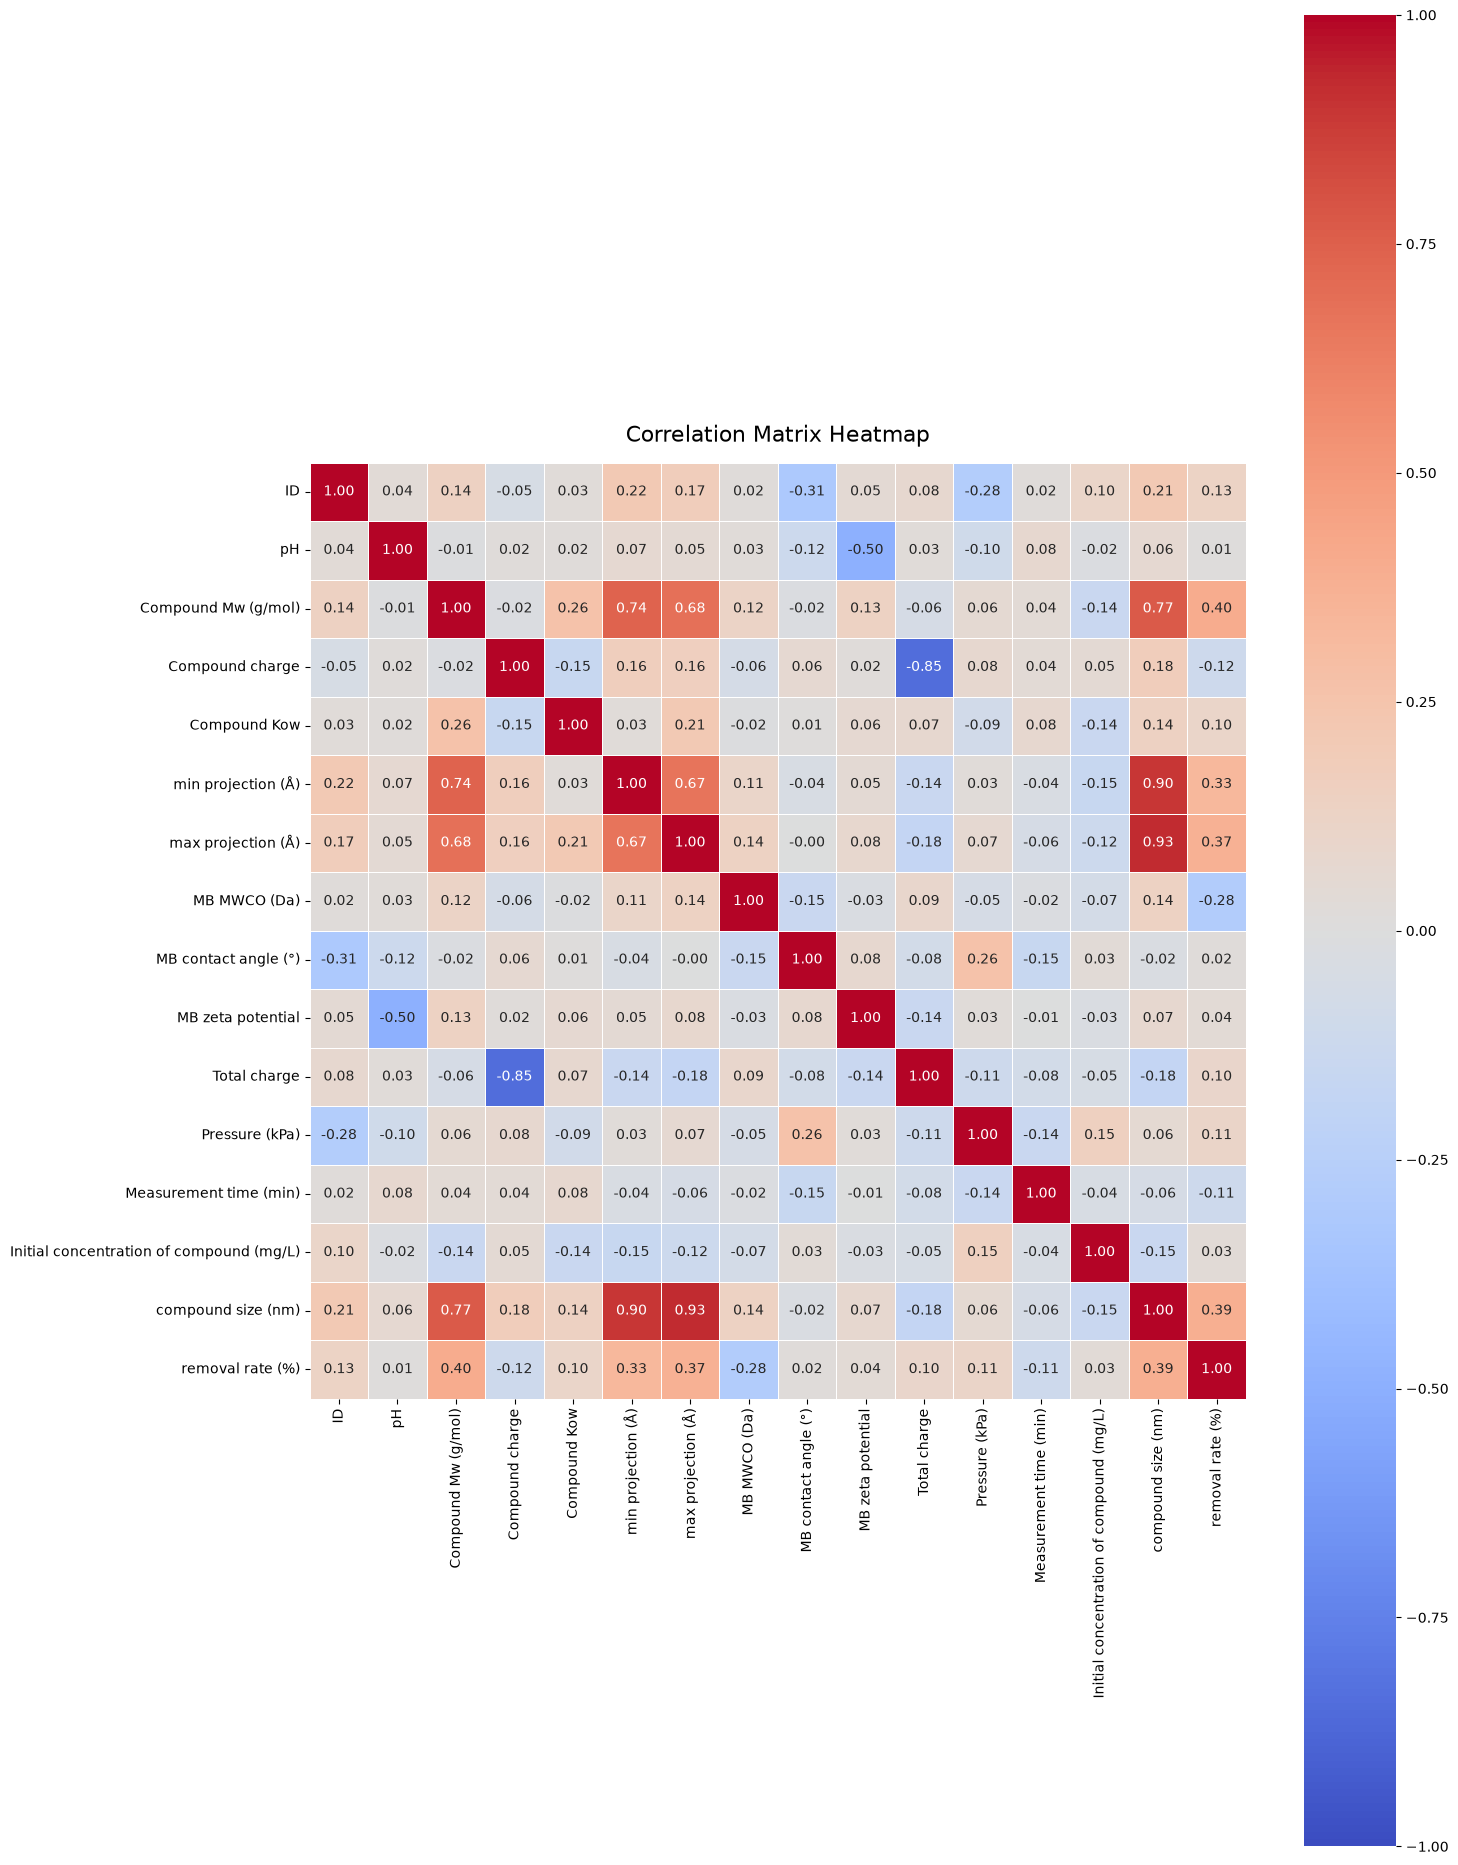

In [11]:
df_num = df.select_dtypes(include=[np.number])
corr = df_num.corr()
# 3. Create a clean heatmap
plt.figure(figsize=(15, 19))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)
plt.title("Correlation Matrix Heatmap", fontsize=16, pad=15)
plt.tight_layout()
plt.show()

In [12]:
# from scipy import stats
# import numpy as np

# z = np.abs(stats.zscore(X))
# mask = (z < 3).all(axis=1)

# X = X[mask]
# Y = Y[mask]
# X

In [13]:
X = X.replace([np.inf, -np.inf], np.nan)
valid_idx = X.dropna().index
X = X.loc[valid_idx]
Y = Y.loc[valid_idx]

In [14]:
print(X.shape)
X

(1906, 6)


,MB MWCO (Da),Compound Mw (g/mol),Total charge,MB contact angle (°),Initial concentration of compound (mg/L),compound size (nm)
0,150,162.229,0.0000,50.0,0.16223,0.512
1,150,113.160,0.0000,50.0,0.11316,0.396
2,150,131.135,0.0000,50.0,0.13114,0.382
3,150,30.026,0.0000,50.0,0.03003,0.221
4,150,60.096,0.0000,50.0,0.06010,0.315
...,...,...,...,...,...,...
1901,200,357.790,1.0000,22.6,0.02000,0.669
1902,200,347.390,0.3711,22.6,0.02000,0.550
1903,200,414.520,-0.9374,22.6,0.02000,0.722
1904,200,733.937,-1.0000,22.6,0.02000,0.798


In [15]:
feature_names = X.columns.tolist()


X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape) 

X_train_gpu = cp.asarray(X_train.values, dtype=cp.float32)
y_train_gpu = cp.asarray(y_train.values, dtype=cp.float32)

Train shape: (1524, 6)
Test shape: (382, 6)


In [16]:
param_space = {
    "n_estimators": hp.quniform("n_estimators",100, 500, 200),
    "max_depth": hp.quniform("max_depth", 3, 7, 2),
    "learning_rate": hp.uniform("learning_rate", 0.01, 0.2),
    "subsample": hp.uniform("subsample", 0.6, 1.0),
    "colsample_bytree": hp.uniform("colsample_bytree", 0.6, 1.0),
    "gamma": hp.uniform("gamma", 0, 0.3),
    "min_child_weight": hp.quniform("min_child_weight", 1, 5, 2)
}

def objective(params):
    params["n_estimators"] = int(params["n_estimators"])
    params["max_depth"] = int(params["max_depth"])
    params["min_child_weight"] = int(params["min_child_weight"])

    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    scores = []

    for train_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train_gpu[train_idx], X_train_gpu[val_idx]
        y_tr, y_val = y_train_gpu[train_idx], y_train_gpu[val_idx]
    
        model = XGBRegressor(
            objective='reg:squarederror',
            random_state=42,
            device="cuda",       # Forces GPU training
            tree_method="hist",  # Fast GPU histogram build
            **params
        )

        model.fit(X_tr, y_tr)
        pred = model.predict(X_val)
    
        # 5-Fold cross-validation on GPU
        scores.append(cuml_r2_score(y_val, pred))
    
    mean_r2 = float(np.mean(scores))
    return {'loss': -mean_r2, 'status': STATUS_OK}

In [17]:
print("Starting Hyperopt optimization...")
trials = Trials()
best_params = fmin(
    fn=objective,
    space=param_space,
    algo=tpe.suggest,
    max_evals=50,  
    trials=trials
)

print("\n--- Optimization Complete ---")
best_params["n_estimators"] = int(best_params["n_estimators"])
best_params["max_depth"] = int(best_params["max_depth"])
best_params["min_child_weight"] = int(best_params["min_child_weight"])

best_cv_score = -trials.best_trial['result']['loss']
print("Best Parameters:", best_params)
print(f"Best CV R² Score: {best_cv_score:.4f}")

Starting Hyperopt optimization...
100%|██████████| 50/50 [03:18<00:00,  3.98s/trial, best loss: -0.7192785382270813]

--- Optimization Complete ---
Best Parameters: {'colsample_bytree': np.float64(0.8207415587076571), 'gamma': np.float64(0.29670978331061915), 'learning_rate': np.float64(0.16481695959156414), 'max_depth': 6, 'min_child_weight': 2, 'n_estimators': 400, 'subsample': np.float64(0.988582128809157)}
Best CV R² Score: 0.7193


In [18]:
final_xgb_model = XGBRegressor(
    objective='reg:squarederror',
    random_state=42,
    device="cuda",
    tree_method="hist",
    **best_params
)
final_xgb_model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,np.float64(0.8207415587076571)
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",'cuda'
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [19]:
xgb_pred = final_xgb_model.predict(X_test)

xgb_mse = mean_squared_error(y_test, xgb_pred)
xgb_rmse = np.sqrt(xgb_mse)
xgb_mae = mean_absolute_error(y_test, xgb_pred)
xgb_r2 = r2_score(y_test, xgb_pred)

print("\n--- Final Test Set Metrics ---")
print(f"MSE: {xgb_mse:.4f}")
print(f"RMSE: {xgb_rmse:.4f}")
print(f"MAE: {xgb_mae:.4f}")
print(f"R² Score: {xgb_r2:.4f}")


--- Final Test Set Metrics ---
MSE: 199.8785
RMSE: 14.1378
MAE: 8.6117
R² Score: 0.7382


/home/aashr/miniforge3/envs/rapids-26.08/lib/python3.12/site-packages/xgboost/core.py:553: UserWarning: [07:03:43] WARNING: /home/conda/feedstock_root/build_artifacts/xgboost-split_1785981408196/work/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


/home/aashr/miniforge3/envs/rapids-26.08/lib/python3.12/site-packages/shap/explainers/_tree.py:265: FutureWarning: In the future, passing feature_perturbation='interventional' without providing a background dataset will raise an error. Please provide a background dataset to continue using the interventional approach or set feature_perturbation='auto' to automatically switch approaches.
  warnings.warn(


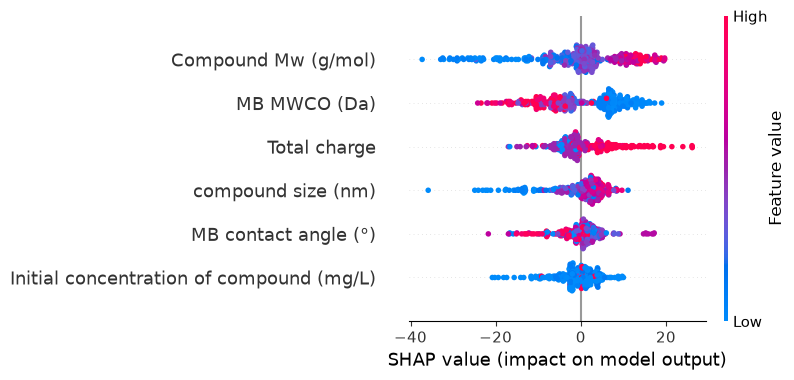

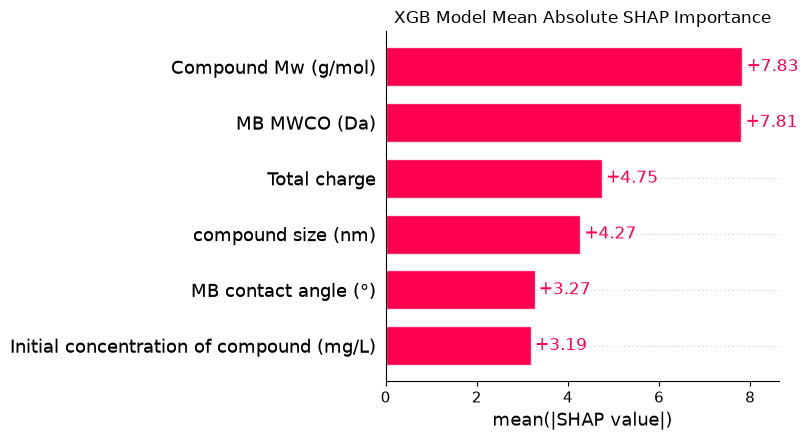


--- Top 6 Most Important Features ---
                                    feature  importance
1                       Compound Mw (g/mol)    7.830894
0                              MB MWCO (Da)    7.809591
2                              Total charge    4.748481
5                        compound size (nm)    4.270209
3                      MB contact angle (°)    3.267977
4  Initial concentration of compound (mg/L)    3.187748


In [20]:
explainer = shap.TreeExplainer(final_xgb_model, feature_perturbation="interventional")
shap_values = explainer(X_test)  # Using the new explainer API format

# Summary Plot
shap.summary_plot(shap_values, X_test)

# Bar Plot
shap.plots.bar(shap_values, max_display=6, show=False)
plt.title("XGB Model Mean Absolute SHAP Importance")
plt.tight_layout()
plt.show()

# FIXED: Extract mean absolute values correctly from the SHAP Explanation object
shap_importance = np.abs(shap_values.values).mean(axis=0)

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": shap_importance
}).sort_values(by="importance", ascending=False)

top6 = feature_importance.head(6)
print("\n--- Top 6 Most Important Features ---")
print(top6)

In [21]:
feature_names = X.columns.tolist()

X_train, X_test, y_train, y_test = cuml_split(
    X, Y, test_size=0.2, random_state=42
)

X_train = cp.asarray(X_train, dtype=cp.float32)
y_train = cp.asarray(y_train, dtype=cp.float32)
X_test = cp.asarray(X_test, dtype=cp.float32)
y_test = cp.asarray(y_test, dtype=cp.float32)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape) 

Train shape: (1524, 6)
Test shape: (382, 6)


In [22]:
param_space_rf = {
    "n_estimators": hp.quniform("n_estimators", 100, 400, 50),
    "max_depth": hp.quniform("max_depth", 6, 14, 2),
    "min_samples_split": hp.choice("min_samples_split", [2, 5, 10]),
    "min_samples_leaf": hp.choice("min_samples_leaf", [1, 2, 4]),
    "max_features": hp.uniform("max_features", 0.4, 0.9), # Fraction of features to consider
    "bootstrap": hp.choice("bootstrap", [True, False])
}

def objective_rf(params):
    # Cast types properly for cuML
    params["n_estimators"] = int(params["n_estimators"])
    params["max_depth"] = int(params["max_depth"])
    
    # K-Fold split manually since sklearn's cross_val_score will break on CuPy arrays
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    r2_scores = []
    
    for train_idx, val_idx in kf.split(X_train.get()): # .get() moves indexes to CPU for KFold splitting
        # Slice CuPy arrays cleanly on the GPU
        X_tr, X_val = X_train[train_idx], X_train[val_idx]
        y_tr, y_val = y_train[train_idx], y_train[val_idx]
        
        # Initialize cuML Random Forest (n_jobs handles CPU fallback, omit it for true GPU usage)
        model = RandomForestRegressor(
            random_state=42,
            n_streams=4,
            **params
        )
        model.fit(X_tr, y_tr)
        
        # Predict and score entirely on the GPU
        preds = model.predict(X_val)
        r2 = cuml_r2_score(y_val, preds)
        r2_scores.append(r2)
        
    mean_r2 = np.mean(r2_scores)
    return {'loss': -mean_r2, 'status': STATUS_OK}

In [ ]:
print("Starting Hyperopt optimization for cuML Random Forest...")
trials_rf = Trials()
best_params_rf = fmin(
    fn=objective_rf,
    space=param_space_rf,
    algo=tpe.suggest,
    max_evals=50,  # Adjust iterations based on your time constraints
    trials=trials_rf
)

# Fix Hyperopt type mappings for index-based hp.choice parameters
bootstrap_options = [True, False]
min_samples_split_options = [2, 5, 10]
min_samples_leaf_options = [1, 2, 4]

best_params_rf["n_estimators"] = int(best_params_rf["n_estimators"])
best_params_rf["max_depth"] = int(best_params_rf["max_depth"])
best_params_rf["bootstrap"] = bootstrap_options[best_params_rf["bootstrap"]]
best_params_rf["min_samples_split"] = min_samples_split_options[best_params_rf["min_samples_split"]]
best_params_rf["min_samples_leaf"] = min_samples_leaf_options[best_params_rf["min_samples_leaf"]]

print("\n--- Optimization Complete ---")
print("Best RF Parameters:", best_params_rf)

Starting Hyperopt optimization for cuML Random Forest...
 60%|██████    | 30/50 [04:15<02:43,  8.16s/trial, best loss: -0.6661249399185181]

In [ ]:
final_rf_model = RandomForestRegressor(random_state=42, n_streams=4, **best_params_rf)
final_rf_model.fit(X_train, y_train)

# Predict on GPU
rf_pred = final_rf_model.predict(X_test)

# Pull variables back to CPU (.get()) just for standard Scikit-Learn evaluation metrics
y_test_cpu = y_test.get()
rf_pred_cpu = rf_pred.get()

rf_mse = mean_squared_error(y_test_cpu, rf_pred_cpu)
rf_rmse = np.sqrt(rf_mse)
rf_mae = mean_absolute_error(y_test_cpu, rf_pred_cpu)
rf_r2 = r2_score(y_test_cpu, rf_pred_cpu)

print("\nRandom Forest Final Test Metrics:")
print(f"MSE: {rf_mse:.4f}")
print(f"RMSE: {rf_rmse:.4f}")
print(f"MAE: {rf_mae:.4f}")
print(f"R² Score: {rf_r2:.4f}")


Random Forest Final Test Metrics:
MSE: 249.3957
RMSE: 15.7923
MAE: 9.2455
R² Score: 0.6734


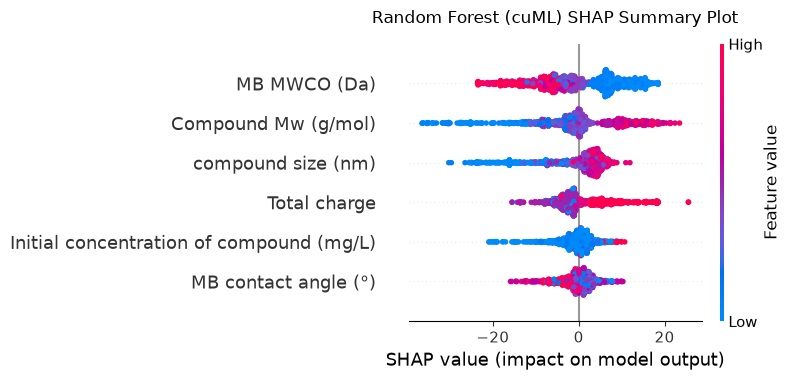

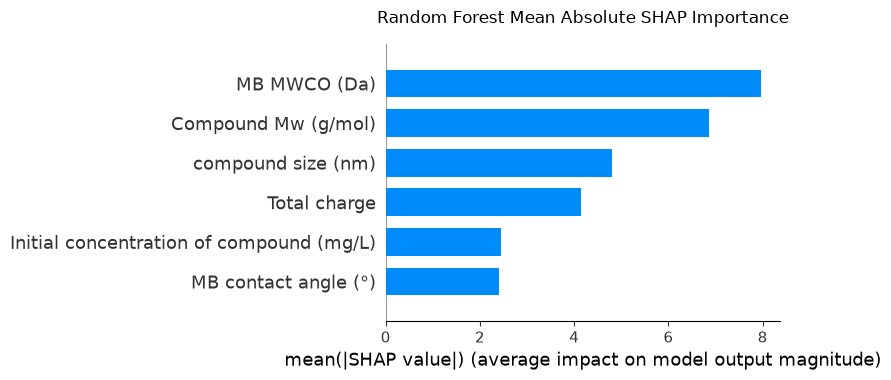


--- Top 6 Most Important Features (Random Forest) ---


,feature,importance
0,MB MWCO (Da),7.968896
1,Compound Mw (g/mol),6.862381
5,compound size (nm),4.800601
2,Total charge,4.136176
4,Initial concentration of compound (mg/L),2.450249
3,MB contact angle (°),2.411878


In [ ]:
from cuml.explainer import TreeExplainer as cuMLTreeExplainer

rf_explainer = cuMLTreeExplainer(model=final_rf_model)
# 2. Compute SHAP values on GPU (using X_train or X_test CuPy arrays)
rf_shap_values = rf_explainer.shap_values(X_train)
# 3. Pull values back to CPU for SHAP visualization plots
rf_shap_values_cpu = rf_shap_values.get()
X_train_cpu = X_train.get()
# Summary Beeswarm Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(
    rf_shap_values_cpu, 
    X_train_cpu, 
    feature_names=feature_names,
    show=False
)
plt.title("Random Forest (cuML) SHAP Summary Plot", pad=15)
plt.tight_layout()
plt.show()
# Mean Absolute SHAP Bar Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(
    rf_shap_values_cpu, 
    X_train_cpu, 
    feature_names=feature_names, 
    plot_type="bar",
    show=False
)
plt.title("Random Forest Mean Absolute SHAP Importance", pad=15)
plt.tight_layout()
plt.show()
# Feature Importance DataFrame
rf_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": np.abs(rf_shap_values_cpu).mean(axis=0)
}).sort_values(by="importance", ascending=False)
print("\n--- Top 6 Most Important Features (Random Forest) ---")
display(rf_importance.head(6))


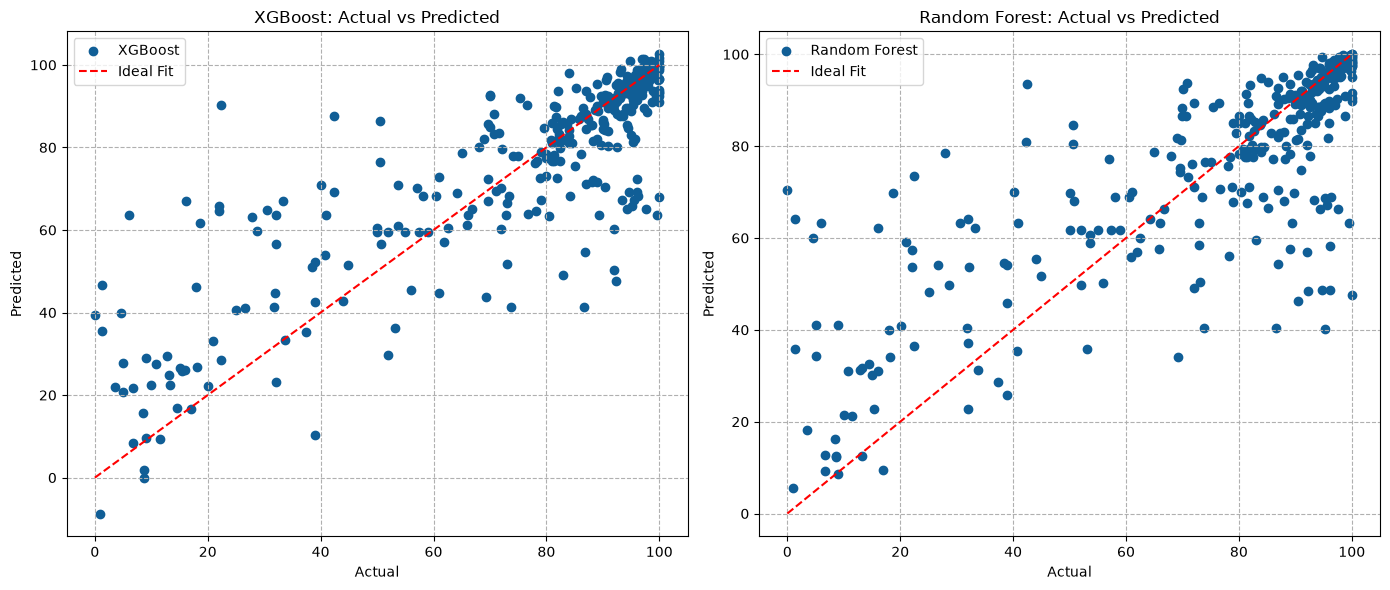

In [ ]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)  
plt.scatter(y_test_cpu, xgb_pred, color="#105e96", label='XGBoost')
plt.plot([y_test_cpu.min(), y_test_cpu.max()], [y_test_cpu.min(), y_test_cpu.max()], 'r--', label='Ideal Fit')
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("XGBoost: Actual vs Predicted")
plt.legend()
plt.grid(True, linestyle='--')

plt.subplot(1, 2, 2) 
plt.scatter(y_test_cpu, rf_pred_cpu, color="#105e96", label='Random Forest')
plt.plot([y_test_cpu.min(), y_test_cpu.max()], [y_test_cpu.min(), y_test_cpu.max()], 'r--', label='Ideal Fit')
plt.xlabel("Actual")
plt.ylabel("Predicted") 
plt.title("Random Forest: Actual vs Predicted")
plt.legend()
plt.grid(True, linestyle='--')

plt.tight_layout()
plt.show()
